In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense
from tensorflow.keras.optimizers import Adam

In [ ]:
# Step 1: Load the data from the uploaded file
try:
    # Read the Excel file, specifying the sheet name
    df = pd.read_excel('data.xlsx', sheet_name='in')
except FileNotFoundError:
    print("Error: 'data.xlsx' not found. Please upload the file to Colab.")
    raise
except Exception as e:
    print(f"Error reading Excel file: {e}")
    raise
# Print column names to debug
print("Column names in DataFrame:", df.columns.tolist())

Column names in DataFrame: ['Timestamp', 'ID', 'pm2.5', 'pm 10', 'temp', 'humi']


In [ ]:
# Step 2: Verify expected columns
expected_columns = ['ID', 'pm2.5', 'pm10', 'temp', 'humi']
for col in expected_columns:
    if col not in df.columns:
        # Handle 'pm 10' vs 'pm10' discrepancy
        if col == 'pm10' and 'pm 10' in df.columns:
            df.rename(columns={'pm 10': 'pm10'}, inplace=True)
            print("Renamed column 'pm 10' to 'pm10'")
        else:
            print(f"Error: Column '{col}' not found. Available columns: {df.columns.tolist()}")
            raise KeyError(f"Column '{col}' not found in the data.")

# Step 3: Calculate 30-minute rolling averages (approximated with 15 rows)
window_size = 15  # ~30 minutes with ~2-minute intervals
rolling_avg = df[['pm2.5', 'pm10', 'temp', 'humi']].rolling(window=window_size, min_periods=1).mean()
rolling_avg['ID'] = df['ID']  # Preserve ID for reference

# Print a sample of rolling averages
print("\n30-Minute Rolling Averages (first 5 rows):")
print(rolling_avg.head())

Renamed column 'pm 10' to 'pm10'

30-Minute Rolling Averages (first 5 rows):
       pm2.5       pm10       temp       humi    ID
0  51.800000  52.100000  30.300000  71.500000  1206
1  51.300000  53.150000  30.400000  71.400000  1207
2  51.733333  53.066667  30.533333  71.233333  1208
3  52.075000  53.675000  30.650000  71.125000  1209
4  52.240000  53.780000  30.780000  71.080000  1210


In [ ]:
# Step 3: Prepare data for CNN
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(rolling_avg[['pm2.5', 'pm10', 'temp', 'humi']])

In [ ]:
# Create sequences
sequence_length = 3
X, y = [], []
for i in range(len(scaled_data) - sequence_length):
    X.append(scaled_data[i:i + sequence_length])
    y.append(scaled_data[i + sequence_length])
X = np.array(X)
y = np.array(y)

Epoch 1/100


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.1572 - val_loss: 0.0502
Epoch 2/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0131 - val_loss: 0.0163
Epoch 3/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0035 - val_loss: 0.0041
Epoch 4/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.2602e-04 - val_loss: 0.0029
Epoch 5/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 4.7156e-04 - val_loss: 0.0024
Epoch 6/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 4.3472e-04 - val_loss: 0.0018
Epoch 7/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.9667e-04 - val_loss: 0.0016
Epoch 8/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3.9258e-04 - val_loss: 0.0015
Epoch 9/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3.9016e-04 - val_loss: 0.0013
Epoch 10/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 4.0535e-04 - val_loss: 0.0013
Epoch 11/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 4.0930e-04 - val_loss: 0.0012
Epoch 12/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s

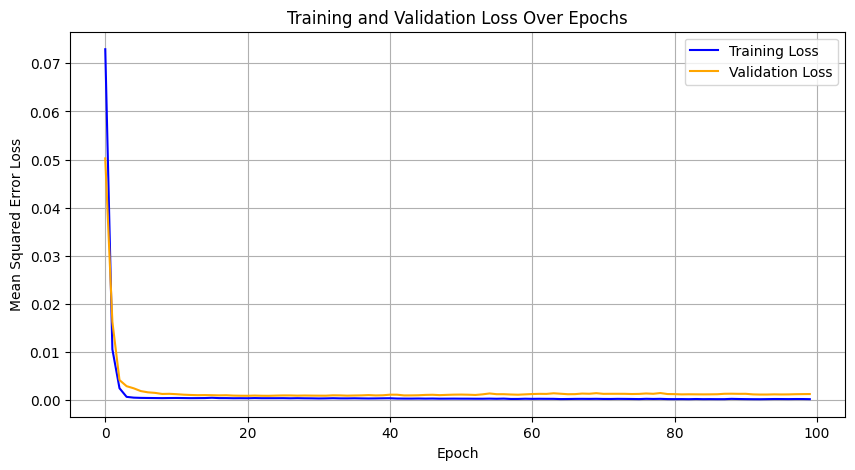

In [ ]:

# Step 4: Build and train CNN model
model = Sequential([
    Conv1D(filters=16, kernel_size=2, activation='relu', input_shape=(sequence_length, 4)),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(10, activation='relu'),
    Dense(4)  # Output: pm2.5, pm10, temp, humi
])

model.compile(optimizer=Adam(learning_rate=0.01), loss='mse')

# Train the model
history = model.fit(X, y, epochs=100, validation_split=0.2, verbose=1)

# Step 5: Plot training and validation loss
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss', color='blue')
plt.plot(history.history['val_loss'], label='Validation Loss', color='orange')
plt.title('Training and Validation Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error Loss')
plt.legend()
plt.grid(True)
plt.show()



In [ ]:
# Step 7: Predict values and compare with actual for first 100 sequences
predictions = model.predict(X[:100], verbose=0)  # Predict only first 100 sequences
predictions = scaler.inverse_transform(predictions)
actual = scaler.inverse_transform(y[:100])

# Predict the next window
last_sequence = scaled_data[-sequence_length:]
last_sequence = last_sequence.reshape((1, sequence_length, 4))
predicted_scaled = model.predict(last_sequence, verbose=0)
predicted_next = scaler.inverse_transform(predicted_scaled)[0]

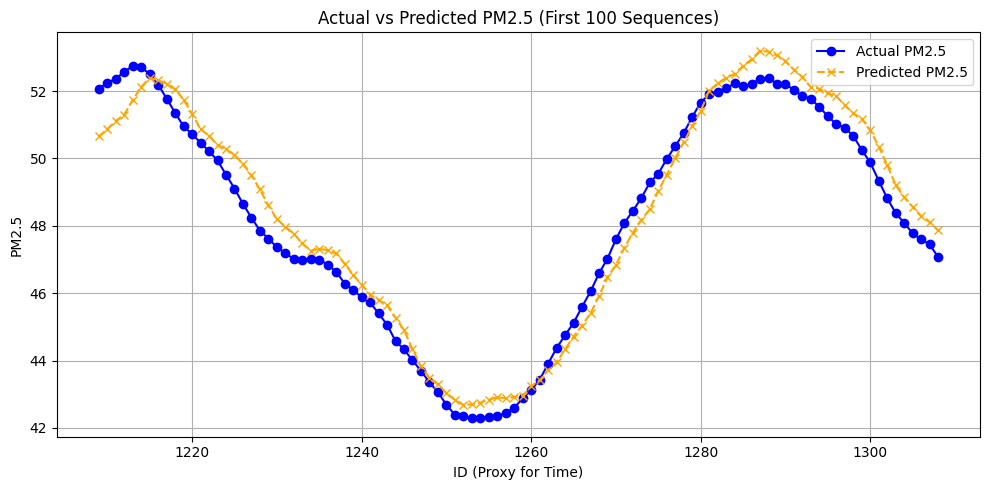

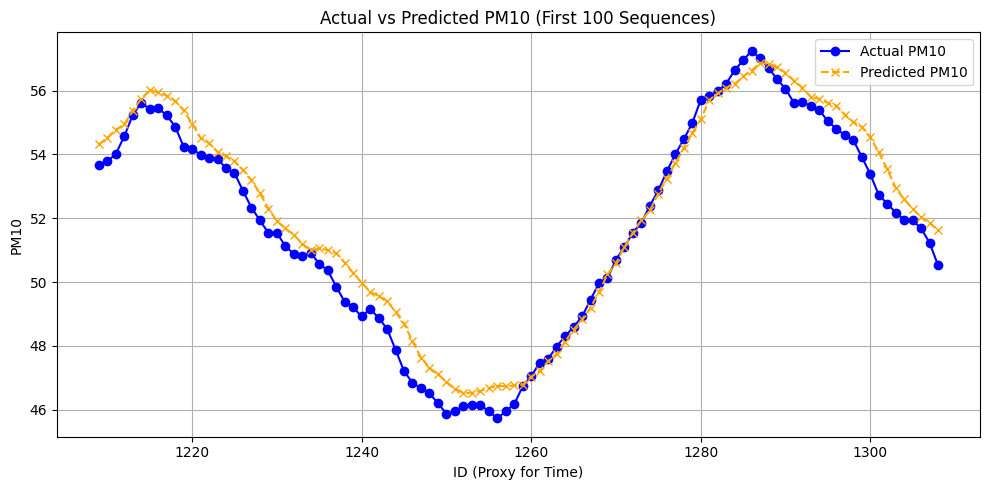

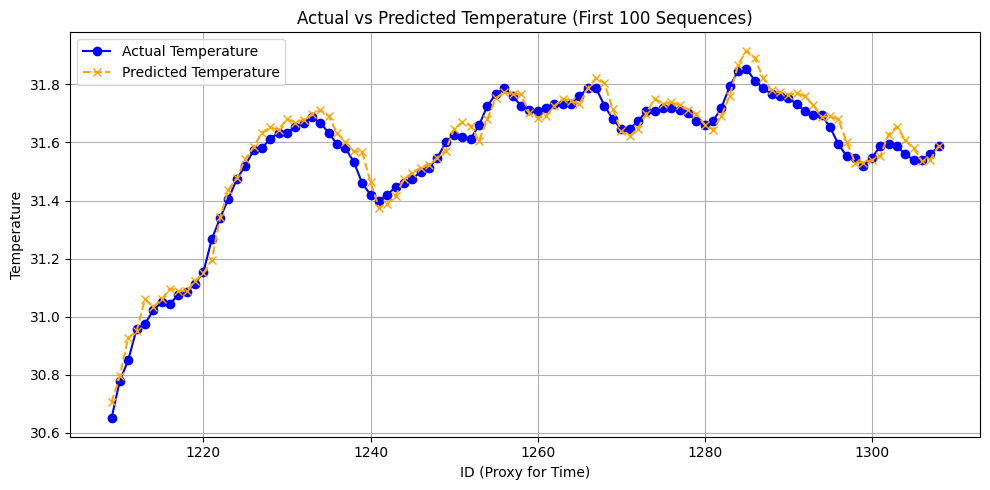

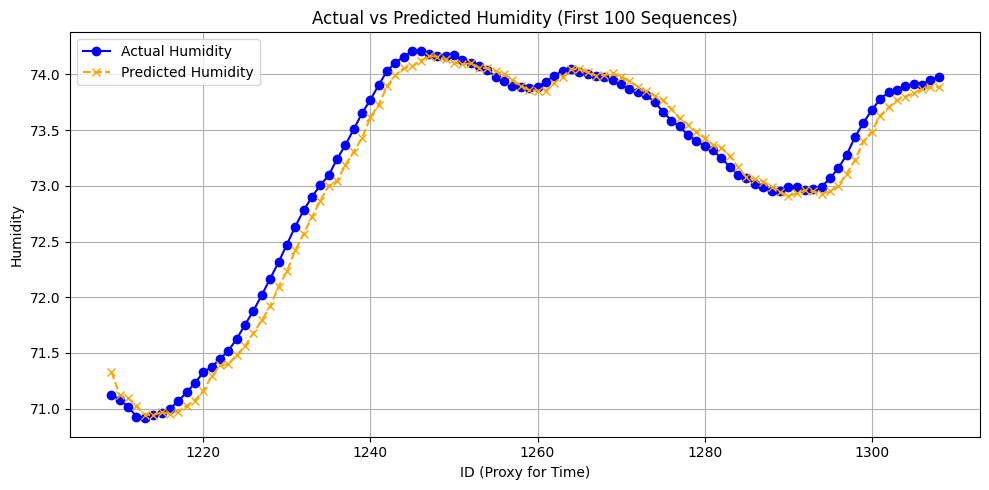


Predicted next 30-minute window averages:
PM2.5: 39.09
PM10: 43.07
Temperature: 30.87
Humidity: 76.26


In [ ]:
# Step 8: Plot actual vs predicted values for first 100 sequences
features = ['PM2.5', 'PM10', 'Temperature', 'Humidity']
ids = rolling_avg['ID'][sequence_length:sequence_length+100].reset_index(drop=True)

for i, feature in enumerate(features):
    plt.figure(figsize=(10, 5))
    plt.plot(ids, actual[:, i], label=f'Actual {feature}', color='blue', marker='o', linestyle='-')
    plt.plot(ids, predictions[:, i], label=f'Predicted {feature}', color='orange', marker='x', linestyle='--')
    # Add the next predicted value
    next_id = ids.iloc[-1] + 1  # Increment ID for the next window
    # plt.scatter([next_id], [predicted_next[i]], color='red', label=f'Next Predicted {feature}', marker='*', s=100)
    plt.title(f'Actual vs Predicted {feature} (First 100 Sequences)')
    plt.xlabel('ID (Proxy for Time)')
    plt.ylabel(feature)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Print the next window's predicted values
print("\nPredicted next 30-minute window averages:")
for i, feature in enumerate(features):
    print(f"{feature}: {predicted_next[i]:.2f}")